### AI Note: Code assisted with generative AI will have a comment with it. 

### My first notebook is also in the github named "LabActivity07-1"

In [29]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")  

col_names= ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\glass.csv", header=None, names=col_names)

class_names = {1: "building_float", 2: "building_nonfloat", 3: "vehicle_float", 
               5: "containers", 6: "tableware", 7: "headlamps"}
features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

X = glass[features]
y = glass["type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

In [30]:
display(X_train[features].agg(["mean", "std", "min", "max"]))

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
mean,1.518430,13.397895,2.678713,1.422807,72.658772,0.475439,9.005614,0.184795,0.058772
std,0.003125,0.832871,1.458232,0.493205,0.789970,0.567826,1.530439,0.522981,0.096627
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000


In [31]:
train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

display(pd.DataFrame({"Train Count": train_counts, "Test Count": test_counts}))

,Train Count,Test Count
type,,
1,56,14
2,61,15
3,14,3
5,10,3
6,7,2
7,23,6


In [32]:
y_train.value_counts(normalize=True)

type
2    0.356725
1    0.327485
7    0.134503
3    0.081871
5    0.058480
6    0.040936
Name: proportion, dtype: float64

In [33]:
class_proportions = y_train.value_counts(normalize=True).sort_index()

proportion_tile = np.tile(class_proportions.values, (len(y_train), 1))

log_loss(y_train, proportion_tile, labels=class_proportions.index)

1.5048600948064486

Part 2.1

- The most common classes are classes 1 and 2, while the least common classes are classes 5 and 6. 

- The accuracy of a model always predicting the most common class is 35.76%, indicated by the proportion of the most common class, 0.3567. 

- Our calculated log loss of 1.505 is lower than ln(6) because we calculate the base-rate log loss. Instead of treating every category the same, our base-rate log loss factors in how many glass fragments there actually are in each category. 

In [34]:
oxides = ["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

oxide_sums = X_train[oxides].sum(axis=1)
print(oxide_sums.describe())

count    171.000000
mean      99.882807
std        0.103471
min       99.560000
25%       99.815000
50%       99.890000
75%       99.960000
max      100.100000
dtype: float64


In [35]:
#I used Gen AI to speed up the pipeline process. 

pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(C=np.inf, max_iter=50000))
])

cv_results = cross_validate(
    pipeline, 
    X_train, 
    y_train, 
    cv=cv, 
    scoring=['neg_log_loss', 'accuracy']
)

print(-cv_results['test_neg_log_loss'].mean())
print(cv_results['test_accuracy'].mean())

pipeline.fit(X_train, y_train)
coefficients = pd.DataFrame(
    pipeline.named_steps['classifier'].coef_, 
    columns=features, 
    index=class_names.values()
)
print(coefficients)

4.207235578070761
0.626218487394958
                          RI         Na         Mg         Al         Si  \
building_float    -21.411147 -37.218371 -12.094765 -20.551965 -27.421104   
building_nonfloat -20.155026 -41.901892 -23.590087 -21.056040 -32.294340   
vehicle_float     -26.906378 -30.651590   0.504124 -16.082595 -23.655148   
containers        -20.572437 -36.161702 -17.828766 -11.733685 -24.212101   
tableware          44.946896  70.139867  19.062251  40.591321  44.124621   
headlamps          44.098092  75.793688  33.947244  28.832964  63.458071   

                           K         Ca         Ba         Fe  
building_float      4.164388  -2.911400   4.763640  21.038900  
building_nonfloat   0.569986 -13.242208   0.302775  21.278512  
vehicle_float       6.943834  13.335618   7.617360  20.654666  
containers          3.285301  -2.482152   3.898695  20.828778  
tableware         -57.886528 -11.469807 -53.139282 -61.376959  
headlamps          42.923019  16.769949  36.556

In [36]:
#I used Gen AI to copy and apply the VIF code from Lab 3 to this lab. 
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X_train[features])
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=features,
    name="VIF",
)
vif.round(2).sort_values(ascending=False)

Ca    335.02
Mg    291.89
Na     90.46
Si     83.36
K      45.36
Ba     38.51
Al     33.85
RI     11.53
Fe      1.35
Name: VIF, dtype: float64

Part 2.2

- I'm seeing that the oxide weight percentages are coming out very very similar and overall very uniform. 

- These VIF values are all over the place, meaning that the coefficients we calculated earlier are heavily correlated to each other. 

- This model has a worse log loss despite its accuracy because accuracy isn't a good metric and because these multicollinear predictors can get very overconfident. This overconfidence results in heavy log loss penalties. 

In [37]:
# I used Gen AI to adapt the regularized grid + 1-SE rule from the in-class notebook.

ll_base = log_loss(y_train, proportion_tile, labels=class_proportions.index)

def cv_scores(model):
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["neg_log_loss", "accuracy"])
    return {
        "log loss (mean)": -res["test_neg_log_loss"].mean(),
        "log loss (sd)": res["test_neg_log_loss"].std(),
        "accuracy (mean)": res["test_accuracy"].mean(),
        "accuracy (sd)": res["test_accuracy"].std(),
    }

def make_model(C, l1_ratio):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga",
                                     max_iter=50000, random_state=48)),
    ])

C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
l1_ratios = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}

all_results = pd.DataFrame([{"model": name, "C": C, **cv_scores(make_model(C, r))}
                            for name, r in l1_ratios.items() for C in C_values])

best = all_results.loc[all_results["log loss (mean)"].idxmin()]
cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)

candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)
candidates["nonzero coefs (of 54)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])
]
simplest = candidates.sort_values(["nonzero coefs (of 54)", "C"]).iloc[0]

C_best, method_best, l1_best = simplest["C"], simplest["model"], simplest["l1_ratio"]
model_best = make_model(C_best, l1_best)

print(best['model'])
print(best['C'])
print(best['log loss (mean)'])
print(method_best)
print(l1_best)
print(C_best)
print(int(simplest['nonzero coefs (of 54)']))

ridge
0.3
1.037358990623939
enet 0.75
0.75
0.3
27


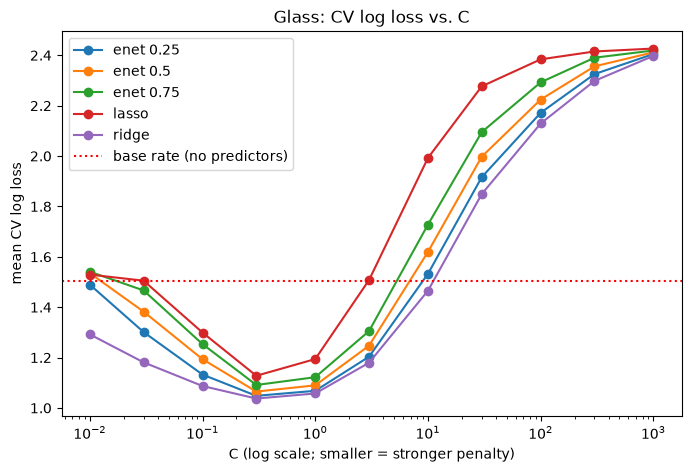

In [38]:
# I used Gen AI to adapt the CV log loss plot from the in-class notebook.
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["log loss (mean)"], marker="o", label=name)
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV log loss", title="Glass: CV log loss vs. C")
ax.legend()
plt.show()

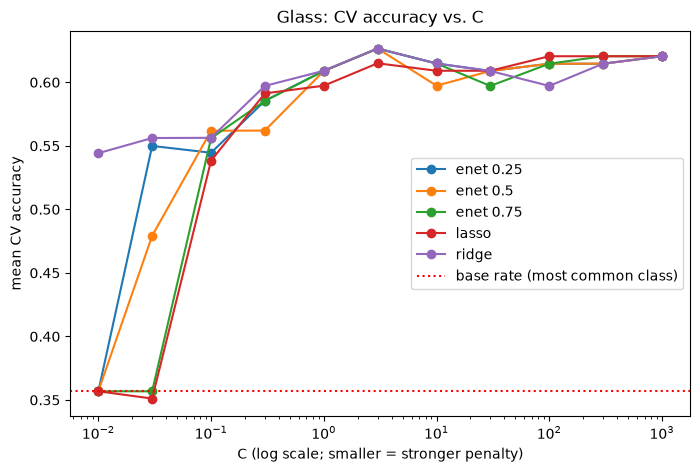

In [39]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["accuracy (mean)"], marker="o", label=name)
ax.axhline(class_proportions.max(), color="red", ls=":", label="base rate (most common class)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV accuracy", title="Glass: CV accuracy vs. C")
ax.legend()
plt.show()

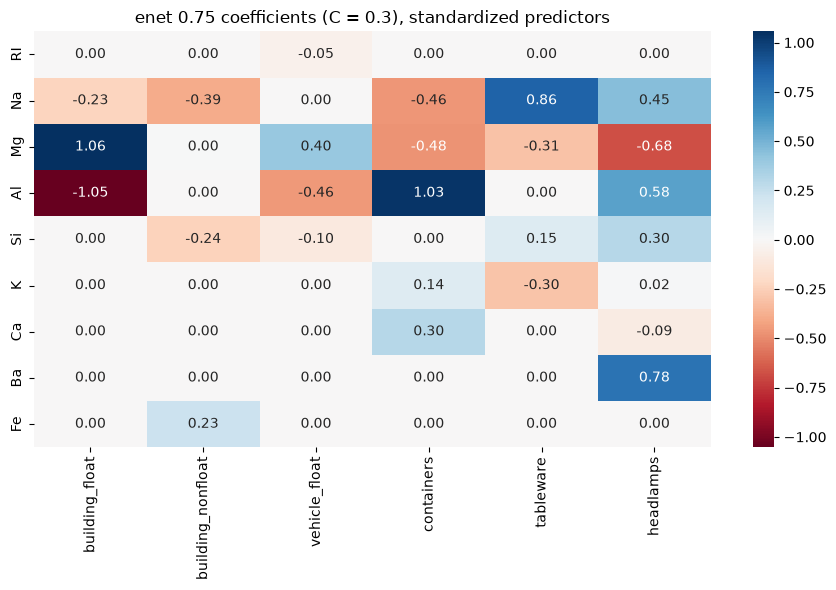

In [40]:
# I used Gen AI to adapt the coefficient heatmap code.
model_best = make_model(C_best, l1_best)
model_best.fit(X_train, y_train)

coef_table = pd.DataFrame(
    model_best.named_steps["model"].coef_.T,
    index=features,
    columns=[class_names[c] for c in model_best.classes_],
)

plt.figure(figsize=(9, 6))
sns.heatmap(coef_table, annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title(f"{method_best} coefficients (C = {C_best}), standardized predictors")
plt.tight_layout()
plt.show()

In [41]:
print(np.exp(coef_table.loc["Ba", "headlamps"] - coef_table.loc["Ba", "building_float"]))
print(np.exp(coef_table.loc["Mg", "building_float"] - coef_table.loc["Mg", "headlamps"]))

2.179731509500642
5.672404920040719


Part 2.3

- Ridge at C = 0.3 has the lowest log loss, but the one-standard-error rule selects enet 0.75 with C = 0.3 with 27 remaining non-zero coefficients. 

- C = 3 has the highest average accuracy. Comparing to the lowest log loss at C = 0.3, this means that the model penalizes heavier when C is closer to 0.3, while penalties are much safer when C is closer to 3. 

- A large C means that regularization is weaker, meaning higher coefficients. Accuracy is higher because the probability of a correct prediction increases, which can also bring overconfidence in a model and cause huge log loss penalties. This gets us a high accuracy and low log loss. 

- The features with a nonzero coefficient for only one class are Ri, Ba, and Fe.

- Headlamps vs building_float has a factor of 2.18, while building_float vs headlamps has a factor of 5.67. 

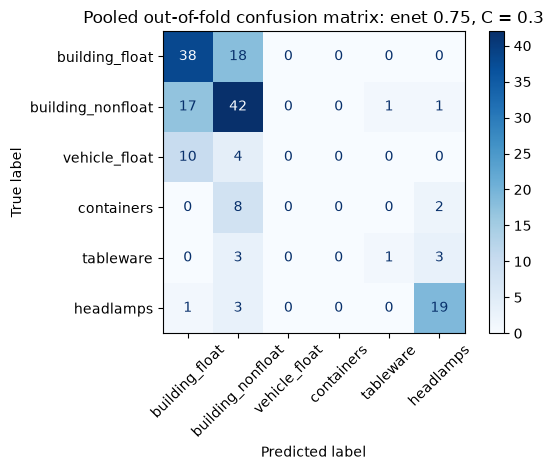

,precision,recall,n (train)
building_float,0.576,0.679,56
building_nonfloat,0.538,0.689,61
vehicle_float,0.000,0.000,14
containers,0.000,0.000,10
tableware,0.500,0.143,7
headlamps,0.760,0.826,23


In [42]:
# I used Gen AI to adapt cv_pred and the confusion matrix code.
def cv_pred(model):
    return cross_val_predict(model, X_train, y_train, cv=cv)

y_pred_log = cv_pred(model_best)

labels = sorted(class_names)                
names = [class_names[c] for c in labels]

ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_log, labels=labels, display_labels=names,
    xticks_rotation=45, cmap="Blues"
)
plt.title(f"Pooled out-of-fold confusion matrix: {method_best}, C = {C_best}")
plt.tight_layout()
plt.show()

pr_table = pd.DataFrame({
    "precision": precision_score(y_train, y_pred_log, labels=labels, average=None, zero_division=0),
    "recall": recall_score(y_train, y_pred_log, labels=labels, average=None, zero_division=0),
    "n (train)": y_train.value_counts().reindex(labels).values,
}, index=names)
pr_table.round(3)

Part 2.4

- The model almost never predicts vehicle_float and containers correctly. 

- Vehicle_float is very commonly mistaken for building_float. Seeing that both are already similarily manufactured and classified together, their chemical composition can also be easily mistaken for the other. 

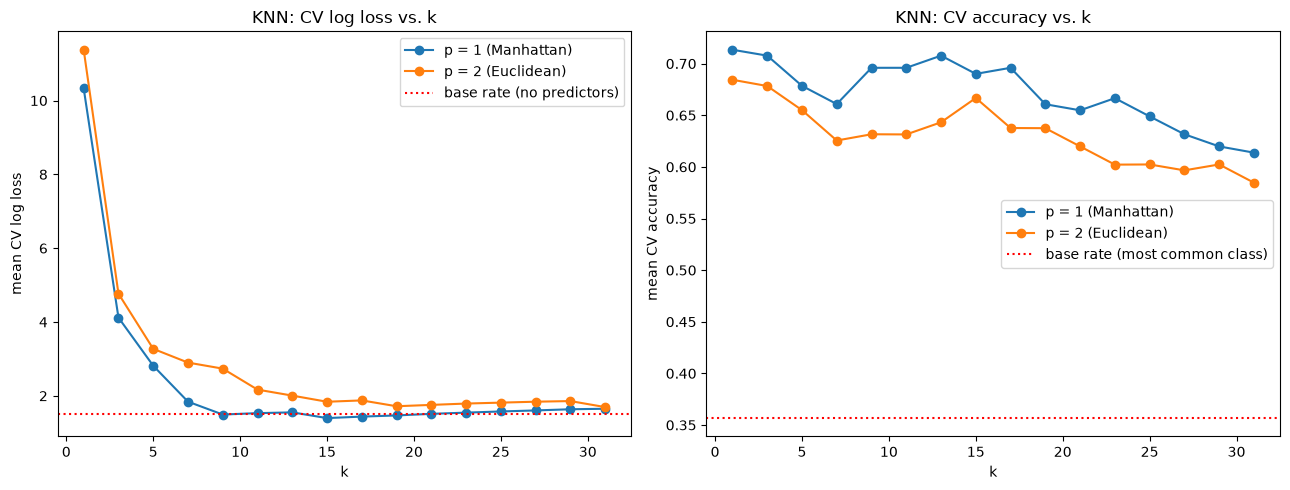

In [43]:
def make_knn(k, p=2):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, p=p)),
    ])

k_values = range(1, 32, 2) 
p_values = [1, 2]

knn_results = pd.DataFrame([{"k": k, "p": p, **cv_scores(make_knn(k, p))}
                            for p in p_values for k in k_values])

# I used Gen AI to assist with plotting the KNN results.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for p, g in knn_results.groupby("p"):
    label = "p = 1 (Manhattan)" if p == 1 else "p = 2 (Euclidean)"
    axes[0].plot(g["k"], g["log loss (mean)"], marker="o", label=label)
    axes[1].plot(g["k"], g["accuracy (mean)"], marker="o", label=label)

axes[0].axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
axes[0].set(xlabel="k", ylabel="mean CV log loss", title="KNN: CV log loss vs. k")
axes[1].axhline(class_proportions.max(), color="red", ls=":", label="base rate (most common class)")
axes[1].set(xlabel="k", ylabel="mean CV accuracy", title="KNN: CV accuracy vs. k")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

best_ll = knn_results.loc[knn_results["log loss (mean)"].idxmin()]
best_acc = knn_results.loc[knn_results["accuracy (mean)"].idxmax()]
k_best, p_best = int(best_ll["k"]), int(best_ll["p"])
model_knn = make_knn(k_best, p_best)

Part 3.1

- k = 15 and p = 1 give the lowest CV log loss. 

- If I'd chosen (k,p) by accuracy, I'd have chosen k=1 and p=1. This k has a great accuracy and poor log loss because of overconfidence once again. There is a good probabiility of a correct prediction, but this causes overconfidence in the model resulting in heavy log loss penalties. 

In [44]:
# I used Gen AI to write the out-of-fold probability probability code. 
proba_knn = cross_val_predict(model_knn, X_train, y_train, cv=cv, method="predict_proba")

classes = np.sort(y_train.unique())
true_idx = np.searchsorted(classes, y_train.values)
p_true = proba_knn[np.arange(len(y_train)), true_idx]

zero_mask = p_true == 0
print(zero_mask.sum())
display(y_train[zero_mask].map(class_names).value_counts())

eps = np.finfo(float).eps
per_frag_loss = -np.log(np.clip(p_true, eps, 1))

print(per_frag_loss.mean())
print(per_frag_loss[zero_mask].sum() / per_frag_loss.sum())
print(per_frag_loss[~zero_mask].mean())

3


type
headlamps     2
containers    1
Name: count, dtype: int64

1.399095709354062
0.45196678974324317
0.7804428936440069


Part 3.2

- There are 3 fragments that get a probability of exactly 0 for their true class. These fragments come from the headlamps and containers classes. 

- Each of these replaced fragments adds an average 1.4 to the log loss and altogether take up a total of 45.2% of the final log loss penalty. The remaining fragments each have an average log loss of 0.79. 

,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
enet 0.75 (C = 0.3),1.0912,0.1711,0.5854,0.0575
"KNN (k = 15, p = 1)",1.3967,0.4744,0.6901,0.0437


,enet 0.75 (C = 0.3),"KNN (k = 15, p = 1)",n (train)
building_float,0.679,0.964,56
building_nonfloat,0.689,0.721,61
vehicle_float,0.000,0.000,14
containers,0.000,0.200,10
tableware,0.143,0.000,7
headlamps,0.826,0.783,23


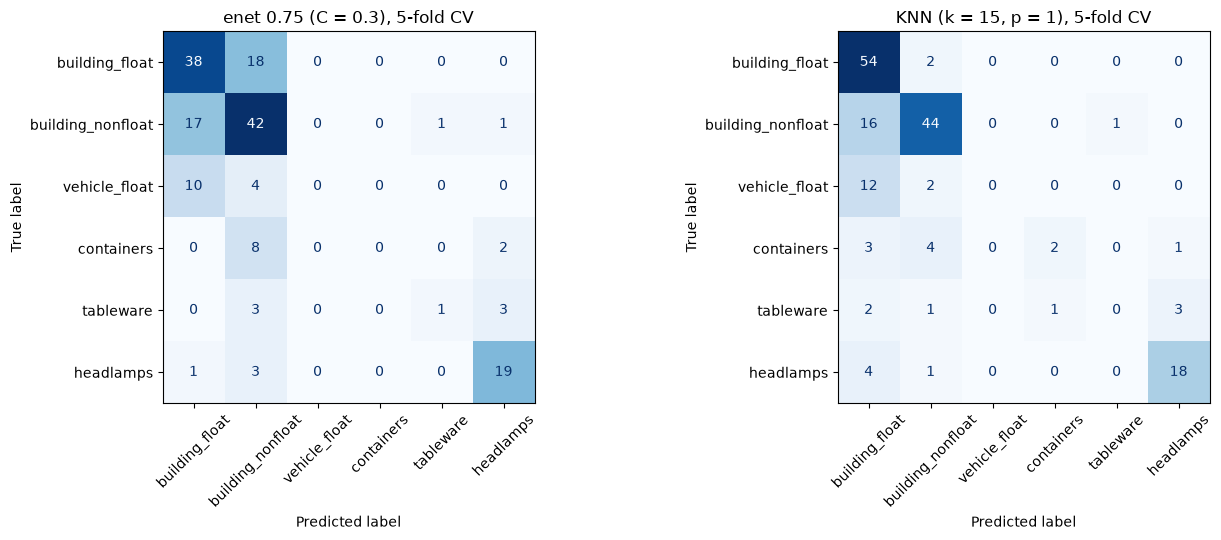

In [45]:
# I used Gen AI to adapt the model comparison code from the in-class notebook (cells 29-31).
y_pred_knn = cv_pred(model_knn)

log_name = f"{method_best} (C = {C_best})"
knn_name = f"KNN (k = {k_best}, p = {p_best})"

summary = pd.DataFrame({
    log_name: cv_scores(model_best),
    knn_name: cv_scores(model_knn),
}).T
display(summary.round(4))

recall_table = pd.DataFrame({
    log_name: recall_score(y_train, y_pred_log, labels=labels, average=None, zero_division=0),
    knn_name: recall_score(y_train, y_pred_knn, labels=labels, average=None, zero_division=0),
    "n (train)": y_train.value_counts().reindex(labels).values,
}, index=names)
display(recall_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, pred) in zip(axes, [(log_name, y_pred_log), (knn_name, y_pred_knn)]):
    ConfusionMatrixDisplay.from_predictions(
        y_train, pred, labels=labels, display_labels=names,
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45
    )
    ax.set_title(f"{name}, 5-fold CV")
plt.tight_layout()
plt.show()

Part 3.3

- Our logistic model has an average CV log loss of 1.09, while our KNN model has an average log loss of 1.4. The KNN model has a higher average CV accuracy with a 0.69, while our logistic model sits at 0.59. In the end, the logistic model is "less worse" with its lower CV log loss. 

- KNN's higher accuracy comes from the large amount of building_float and building_nonfloat predictions. This overconfidence can be seen in the amount of false predictions for both these categories, which compiles many large log loss penalties, making KNN's accuracy not a good reason to prefer KNN. 

- KNN helps the building_float and building_nonfloat categories better then logistic regression does. KNN offers little to no help to the vehicle_float, containers, and tableware categories. This would make precise clusters for the categories it helps and it would leave tiny islands if anything at all for the smaller categories. 

,test log loss,test accuracy
enet 0.75 (C = 0.3),0.8864,0.6512
"KNN (k = 15, p = 1)",0.7538,0.6279


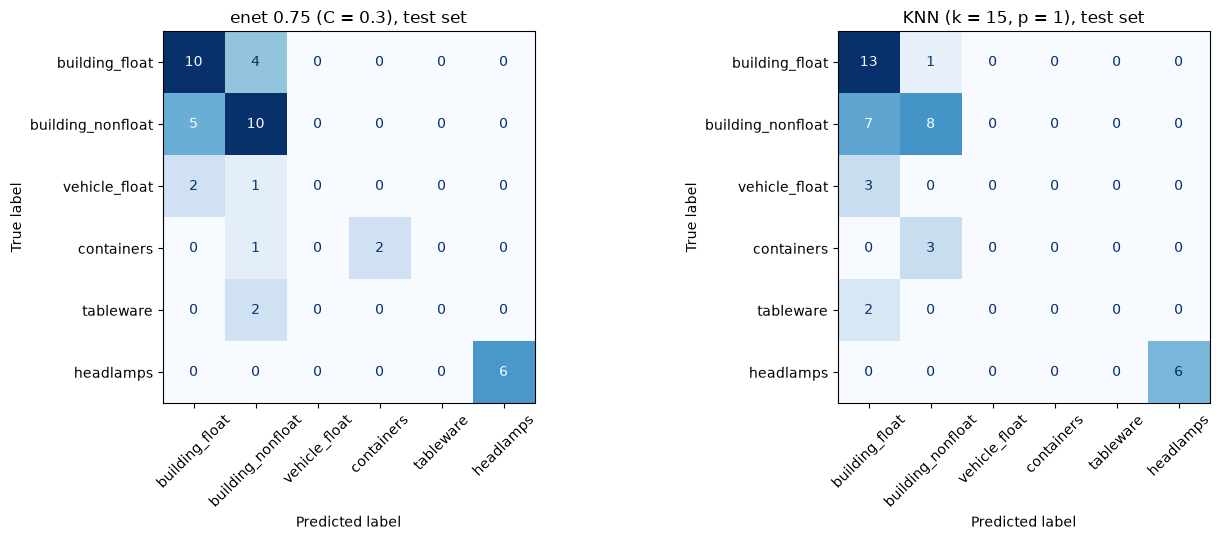

43
0
0.8382244974213292


In [46]:
# I used Gen AI to adapt the testing evaluation code. 
model_best.fit(X_train, y_train)
model_knn.fit(X_train, y_train)

models = [(log_name, model_best), (knn_name, model_knn)]

test_results = pd.DataFrame({
    name: {
        "test log loss": log_loss(y_test, m.predict_proba(X_test), labels=labels),
        "test accuracy": accuracy_score(y_test, m.predict(X_test)),
    }
    for name, m in models
}).T
display(test_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, m) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, m.predict(X_test), labels=labels, display_labels=names,
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45
    )
    ax.set_title(f"{name}, test set")
plt.tight_layout()
plt.show()

# (b) cost of a single p = 0 fragment in KNN's test log loss
n_test = len(y_test)
proba_knn_test = model_knn.predict_proba(X_test)
p_true_test = proba_knn_test[np.arange(n_test), np.searchsorted(labels, y_test.values)]

print(n_test)
print((p_true_test == 0).sum())
print(-np.log(np.finfo(float).eps) / n_test)


Part 3.4

- These test results show an improvement in log loss for both models and a switch in the rankings for both log loss and accuracy from what cross-validation gave. 

- Based on these results, we can look at the performance of the dominant categories, but we can't make any conclusions on the smaller categories. A single fragment with a predicted probability of 0 would ass an average of 0.84 to KNN's test log loss. 